# Q2 (approach 3) - fine-tuning on synthetic (question, chunk) pairs

Same corpus, same block split (147 train / 49 held-out chunks) and same `BAAI/bge-small-en-v1.5` as the
self-supervised notebook. New here: every chunk has 5 questions of different types, and the model is fine-tuned on
**question -> chunk pairs mixed with the original self-supervised sentence-split pairs**.

* Questions were **written by Claude (the coding assistant) reading each chunk** - no API / RAG-system model.
* Train questions come only from the 147 train chunks; evaluation uses questions from the 49 held-out chunks.
* Artefacts: `training_data/` (data + report), `outputs3/heldout/` (model, metrics, figures).

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / 'src').exists(): ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np
from q2_embedder_final import config
from q2_embedder_final.preprocess import load_corpus, block_split, make_pairs
from q2_embedder_final.embed import DenseEmbedder
from q2_embedder_final.evaluate import evaluate_embeddings, results_table
from q2_embedder_final.train import finetune_dense
from q2_embedder_final import main_qa as qa          # also sets the display names used in the tables

OUT = config.OUT_DIR3 / 'heldout'
RETRAIN = False        # False: load outputs3/heldout/finetuned_model if it exists (training takes ~20 min on CPU)

def show(path):
    try:
        from IPython.display import Image, display
        display(Image(filename=str(path)))
    except ImportError:
        print(f'[figure: {path}]')

def md(text):
    try:
        from IPython.display import Markdown, display
        display(Markdown(text))
    except ImportError:
        print(text)

## 1. Data and split
`block_split` holds out contiguous blocks of 6 chunks per document (adjacent chunks overlap by ~50 tokens), so a held-out
question's source text never appears in training.

In [2]:
corpus = load_corpus()
train_idx, test_idx = block_split(corpus)
train_rows, test_rows = qa.load_qa(corpus, train_idx, test_idx)   # also asserts split.json == block_split
print(len(corpus), 'chunks |', len(train_idx), 'train |', len(test_idx), 'held-out')
print(len(train_rows), 'kept train questions |', len(test_rows), 'held-out test questions')
assert not set(r['chunk_id'] for r in train_rows) & set(r['chunk_id'] for r in test_rows)

196 chunks | 147 train | 49 held-out
573 kept train questions | 224 held-out test questions


## 2. Questions: authoring and filtering
Five types per chunk: `factual`, `conceptual`, `argument`, `paraphrase` (avoids the passage's key terms) and `keyword`
(terse search query). Filters (`build_training_data.py`): length, deictic references ("this passage", "page 5"), copied
8-token spans, near-duplicate siblings, and - **train only** - a round-trip check that the baseline ranks the source
chunk in its top 10 of all 196. Test questions are not round-trip filtered, so the test set is not biased toward questions
the baseline already answers.

In [3]:
print((config.TRAINING_DATA_DIR / 'report.md').read_text(encoding='utf-8'))

# Synthetic question data - build report

**Authorship:** every question was written by Claude (the coding assistant) after reading the chunk; no LLM API or RAG-system model was used.
**Round-trip model:** `BAAI/bge-small-en-v1.5` with the bge query prefix; rank = position of the source chunk among all 196 chunks.

## Counts

| split | chunks | questions authored | kept | dropped |
|---|---|---|---|---|
| train | 147 | 735 | 573 | 162 |
| test | 49 | 245 | 224 | 21 |

## Kept questions by type

| type | train kept / authored | test kept / authored |
|---|---|---|
| factual | 118 / 147 | 40 / 49 |
| conceptual | 114 / 147 | 43 / 49 |
| argument | 102 / 147 | 45 / 49 |
| paraphrase | 102 / 147 | 49 / 49 |
| keyword | 137 / 147 | 47 / 49 |

## Drop reasons

| reason | train | test |
|---|---|---|
| copies_chunk_span | 69 | 20 |
| document_reference | 1 | 1 |
| roundtrip_rank_gt_10 | 92 | 0 |

## Baseline rank of the source chunk (all authored questions)

| split | rank 1 | rank <= 3 | ran

In [4]:
# one chunk, all five authored questions (held-out chunk shown so the example is not training data)
cid = test_rows[0]['chunk_id']
print(cid)
print(corpus.texts[corpus.chunk_ids.index(cid)][:500], '...\n')
for r in test_rows:
    if r['chunk_id'] == cid:
        print(f"[{r['qtype']:<10}] (baseline rank {r['rt_rank']:>3})  {r['question']}")

macquarie-0012
A pure omission occurs when a speaker says nothing, in circumstances that do not give any particular meaning to that silence. Take the simplest example. If a company fails entirely to file an MD&A, then the omission of particular information required in the MD&A has no special significance because no information was disclosed. Half-truths, on the other hand, are “representations that state the truth only so far as it goes, while omitting critical qualifying information.” Universal Health Service ...

[factual   ] (baseline rank   1)  What contract-law example about a seller and new roads is used to illustrate an actionable half-truth?
[conceptual] (baseline rank   1)  What is a pure omission according to the Court?
[argument  ] (baseline rank   1)  Why does a company's failure to file any MD&A at all amount to a pure omission rather than a half-truth?
[paraphrase] (baseline rank   5)  When someone says nothing at all and the silence carries no particular meaning, what is

In [5]:
dropped = [json.loads(l) for l in (config.TRAINING_DATA_DIR / 'dropped.jsonl').read_text(encoding='utf-8').splitlines()]
for d in [x for x in dropped if x['drop_reason'].startswith('roundtrip')][:4] + [x for x in dropped if x['drop_reason'] == 'copies_chunk_span'][:3]:
    print(f"{d['drop_reason']:<22} rank={d['rt_rank']:<4} {d['question']}")

roundtrip_rank_gt_10   rank=32   What does Item 303 of SEC Regulation S-K require companies to disclose in their periodic filings?
roundtrip_rank_gt_10   rank=70   On what ground did the Second Circuit conclude that an Item 303 violation alone could sustain a Rule 10b-5 claim?
roundtrip_rank_gt_10   rank=37   A shareholder says a company hid a known regulatory trend likely to hurt revenue; what securities rule did the lawsuit rely on to call that silence unlawful?
roundtrip_rank_gt_10   rank=42   If a speaker simply says nothing, with no earlier statement that becomes misleading, can that be securities fraud under the rule's second prohibition?
copies_chunk_span      rank=1    Which section of the Exchange Act requires issuers to file periodic informational statements?
copies_chunk_span      rank=1    What two circumstances did the Second Circuit say impose a duty on a corporation to disclose omitted facts?
copies_chunk_span      rank=1    What did the Second Circuit say about a failur

## 3. Mixed training pairs
`rounds_ss` are the original self-supervised pairs (two halves of one chunk). `rounds_q` hold the r-th kept question of
every train chunk. Each round has at most one pair per chunk, so a chunk is never its own in-batch negative; batches
never mix rounds. The bge query instruction is prepended to questions only.

In [6]:
rounds_ss = make_pairs(corpus.texts, train_idx)
rounds_q = qa.question_rounds(train_rows, corpus)
print('self-supervised rounds:', [len(r) for r in rounds_ss], '=', sum(map(len, rounds_ss)), 'pairs')
print('question rounds       :', [len(r) for r in rounds_q], '=', sum(map(len, rounds_q)), 'pairs')
q, c, i = rounds_q[0][0]
print('\nexample question pair\n  q:', q, '\n  chunk:', c[:160], '...')

self-supervised rounds: [145, 145, 145, 145] = 580 pairs
question rounds       : [146, 145, 134, 107, 41] = 573 pairs

example question pair
  q: Represent this sentence for searching relevant passages: By roughly how much did Macquarie's share price drop after the February 2018 storage-contract announcement? 
  chunk: No. 22–1165. Argued January 16, 2024—Decided April 12, 2024 Petitioner Macquarie Infrastructure Corporation owns a subsidiary that operates terminals to store b ...


## 4. Fine-tune
Same recipe as the self-supervised run: symmetric InfoNCE, in-batch negatives, 2 epochs, batch 16, lr 2e-5, scale 20.

loaded D:\placemement prep\projects\AIEngineerAssignment-Virallens\AIEngineerAssignment-Virallens\q2_embedder_final\outputs3\heldout\finetuned_model
148 steps | loss first 10: 1.230 -> last 10: 0.416


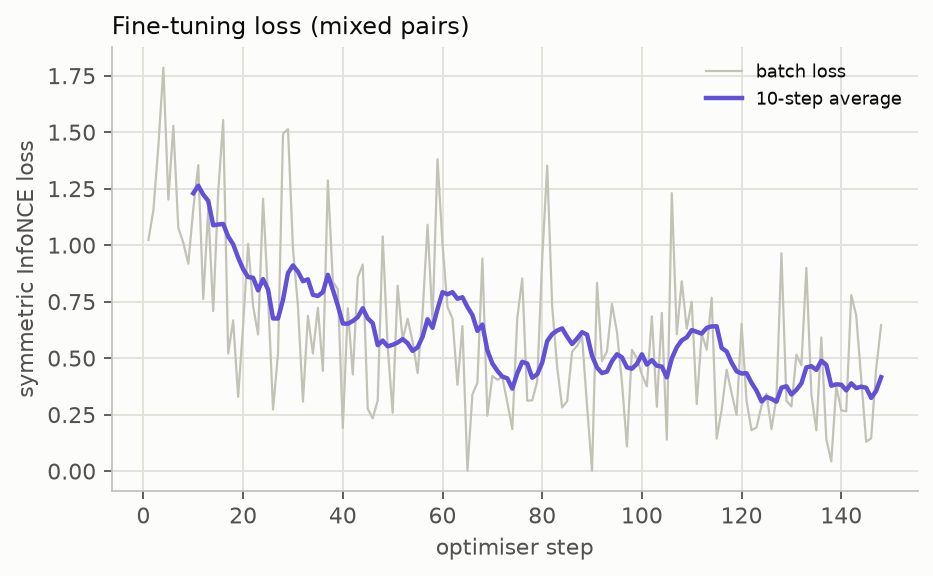

In [7]:
ckpt = OUT / 'finetuned_model'
if ckpt.exists() and not RETRAIN:
    model_qa = DenseEmbedder('custom-finetuned-qa', ckpt)
    log = json.loads((OUT / 'train_log.json').read_text(encoding='utf-8'))
    print('loaded', ckpt)
else:
    model_qa, losses = finetune_dense(rounds_ss + rounds_q, base_model=config.QA_BASELINE_MODEL,
                                      epochs=config.FT_EPOCHS, save_dir=ckpt)
    log = {'losses': losses}
    (OUT).mkdir(parents=True, exist_ok=True)
    (OUT / 'train_log.json').write_text(json.dumps(log), encoding='utf-8')
L = log['losses']
print(f'{len(L)} steps | loss first 10: {np.mean(L[:10]):.3f} -> last 10: {np.mean(L[-10:]):.3f}')
show(OUT / 'fig5_loss.png')

## 5. Retrieval of held-out questions
Each held-out question is embedded (with the bge query instruction) and ranked against chunk embeddings; the gold chunk
is the one it was written from. Headline pool: the 49 held-out chunks. Secondary pool: all 196 chunks. The
self-supervised model is the checkpoint in `outputs2/heldout` (same 147 training chunks).

In [8]:
embedders = {
    'baseline': DenseEmbedder('baseline', config.QA_BASELINE_MODEL),
    'finetuned': DenseEmbedder('finetuned', config.PKG_DIR / 'outputs2/heldout/finetuned_model'),
    'finetuned_qa': model_qa,
}
ret = qa.evaluate_retrieval(embedders, corpus, test_idx, test_rows)
X_all = ret.pop('_X_all'); ret.pop('_ranks')
md(qa.retrieval_markdown(ret))

# Retrieval of held-out questions (224 questions from 49 held-out chunks)

Gold chunk = the chunk a question was written from. Models never saw these chunks or questions in training. `no query prefix` rows omit bge's query instruction.

## Pool = the 49 held-out chunks (headline)

| model | R@1 | R@3 | R@5 | R@10 | MRR | median rank |
|---|---|---|---|---|---|---|
| Baseline (bge-small) | 0.661 | 0.848 | 0.906 | 0.969 | 0.768 | 1 |
| Baseline (bge-small), no query prefix | 0.638 | 0.839 | 0.911 | 0.964 | 0.754 | 1 |
| Self-supervised FT (bge-small) | 0.683 | 0.884 | 0.938 | 0.964 | 0.792 | 1 |
| Self-supervised FT (bge-small), no query prefix | 0.674 | 0.875 | 0.938 | 0.960 | 0.785 | 1 |
| Questions + self-supervised FT (bge-small) | 0.781 | 0.915 | 0.960 | 0.982 | 0.860 | 1 |
| Questions + self-supervised FT (bge-small), no query prefix | 0.768 | 0.929 | 0.951 | 0.978 | 0.853 | 1 |

### Subset: questions whose gold chunk is in the baseline's top 10 (n = 193)

| model | R@1 | R@3 | R@5

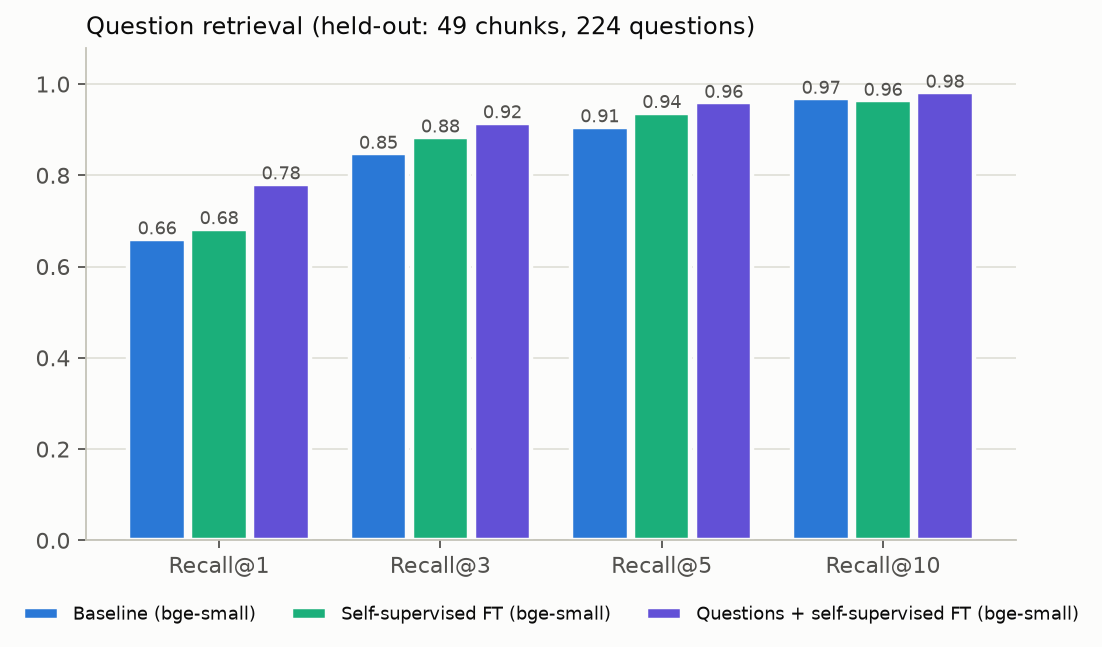

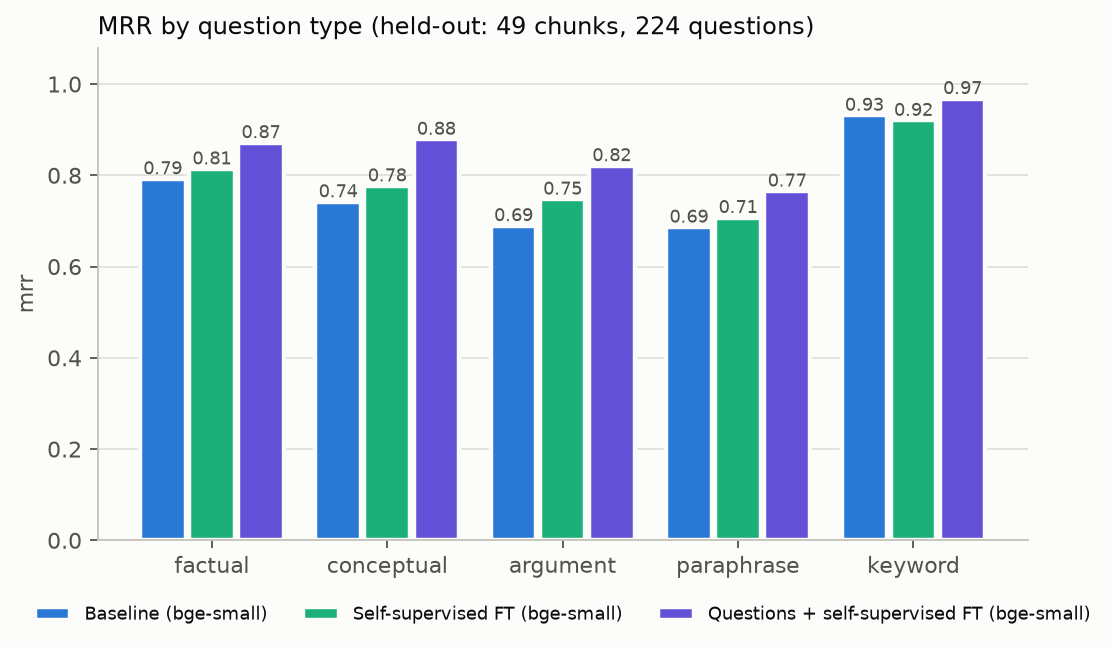

In [9]:
show(OUT / 'fig1_recall.png')
show(OUT / 'fig2_mrr_by_type.png')

## 6. Does the clustering behaviour survive? (49 held-out chunks)
Same protocol as the self-supervised notebook: silhouette, ARI/NMI of k-means at k = #documents, similarity gap, kNN purity.

In [10]:
ev = corpus.subset(test_idx)
X = {k: X_all[k][test_idx] for k in qa.MAIN}
clus = {k: evaluate_embeddings(v, ev.doc_ids, ev.case_ids) for k, v in X.items()}
md(results_table(clus))

| model | sil(doc) | sil(case) | intra-inter sim | pair AUC | ARI@k=docs | NMI@k=docs | kNN-purity@5 | best k |
|---|---|---|---|---|---|---|---|---|
| Baseline (bge-small) | 0.083 | 0.113 | 0.046 | 0.641 | 0.189 | 0.406 | 0.678 | 10 |
| Self-supervised FT (bge-small) | 0.126 | 0.131 | 0.114 | 0.714 | 0.415 | 0.574 | 0.682 | 9 |
| Questions + self-supervised FT (bge-small) | 0.117 | 0.124 | 0.128 | 0.707 | 0.439 | 0.585 | 0.682 | 8 |


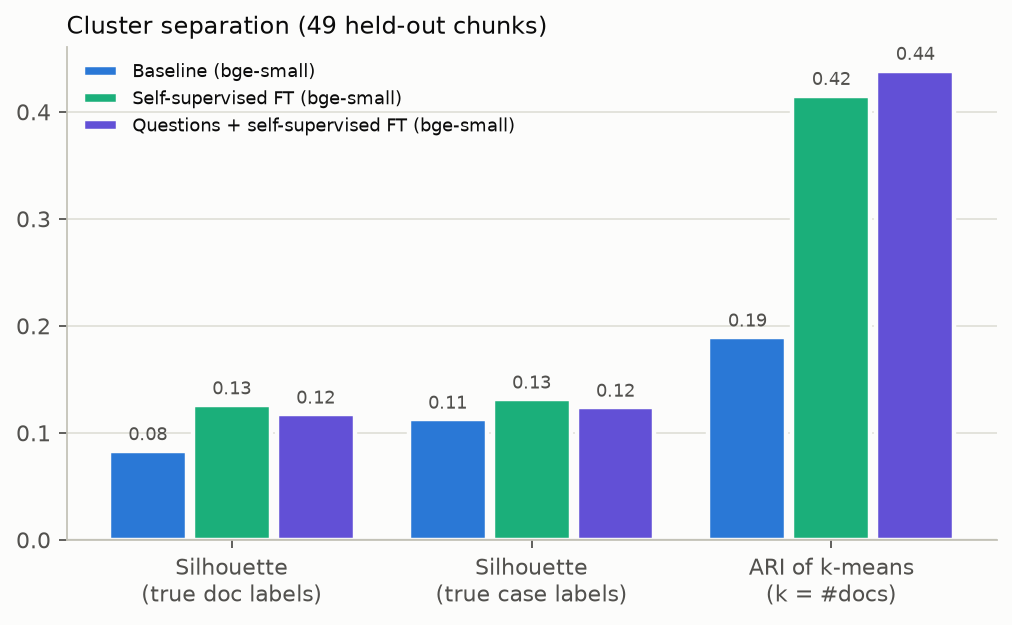

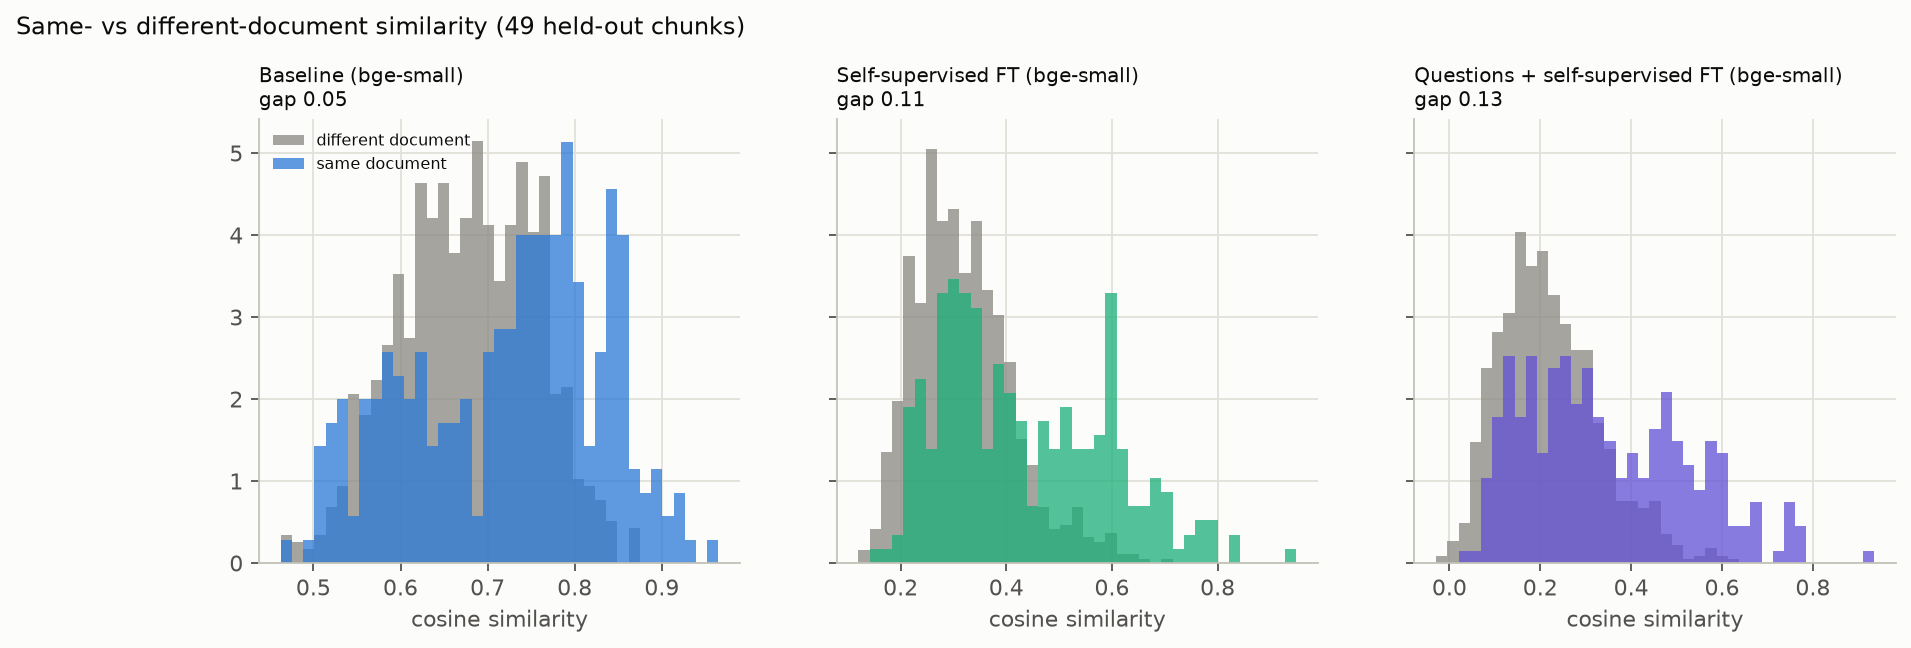

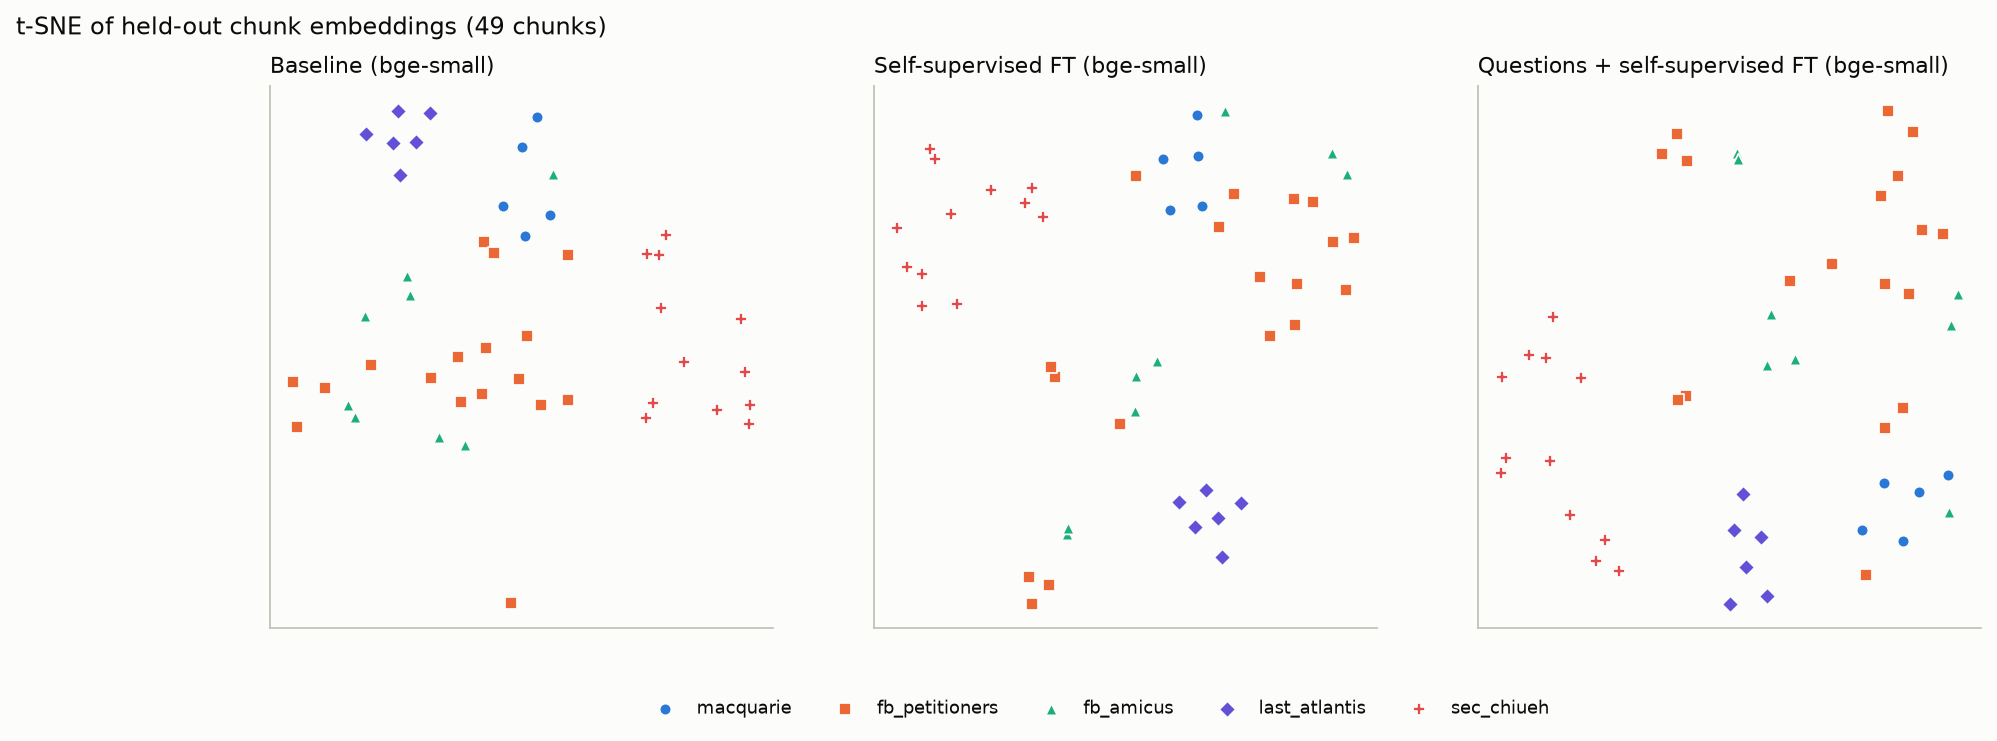

In [11]:
for f in ('fig3_clustering.png', 'fig4_similarity.png', 'fig6_cluster_maps.png'):
    show(OUT / f)

## 7. Probe-query neighbours
Top-3 held-out chunks for five hand-written queries (not LLM-style), embedded with the query prefix.

In [12]:
md((OUT / 'neighbors.md').read_text(encoding='utf-8'))

| query | model | rank | chunk | snippet |
|---|---|---|---|---|
| omission of required disclosure that makes a statement misleading | Baseline (bge-small) | 1 | [FB Pet. Br., pp.26–27] (sim 0.83) | Whether an omission renders a statement false or misleading depends on how a reasonable investor would underst… |
|  | Baseline (bge-small) | 2 | [Macquarie, pp.9–10] (sim 0.79) | Matrixx Initiatives, Inc. v. Siracusano, 563 U. S. 27, 44 (2011) (quoting Rule 10b-5(b)). Statutory context co… |
|  | Baseline (bge-small) | 3 | [Macquarie, pp.8–9] (sim 0.78) | In other words, the difference between a pure omission and a half-truth is the difference between a child not … |
|  | Self-supervised FT (bge-small) | 1 | [FB Pet. Br., pp.26–27] (sim 0.66) | Whether an omission renders a statement false or misleading depends on how a reasonable investor would underst… |
|  | Self-supervised FT (bge-small) | 2 | [Macquarie, pp.8–9] (sim 0.60) | In other words, the difference between a pure omission and a

## 8. Findings and caveats

**Setup.** bge-small fine-tuned on 580 self-supervised pairs + 573 filtered question pairs from the 147 train chunks
(148 steps, loss 1.23 -> 0.42 averaged over the first / last 10 steps). Evaluated on 224 questions from the 49 held-out chunks.

**Retrieval (headline, held-out pool).**

| | R@1 | R@5 | MRR |
|---|---|---|---|
| Baseline bge-small | 0.661 | 0.906 | 0.768 |
| Self-supervised fine-tune | 0.683 | 0.938 | 0.792 |
| **Questions + self-supervised fine-tune** | **0.781** | **0.960** | **0.860** |

* The mixed model beats the baseline by +0.092 MRR and +0.121 R@1, and beats the self-supervised model by +0.067 MRR /
  +0.098 R@1; all four 95% chunk-bootstrap intervals exclude 0. The self-supervised model alone is **not** reliably better
  than the baseline on MRR or R@1 (interval includes 0).
* The ordering is the same on the harder 196-chunk pool (MRR 0.734 vs 0.646 baseline), on the subset of questions the
  baseline already puts in its top 10, and with or without the bge query prefix.
* Gains are largest for `conceptual` (R@1 0.63 -> 0.81), `factual` (0.68 -> 0.80) and `argument` (0.58 -> 0.71) questions;
  `paraphrase` improves less (0.53 -> 0.65); `keyword` queries were already easy (0.89 -> 0.94).

**Clustering (49 held-out chunks).** The mixed model keeps the benefit of the self-supervised model over the baseline
(doc silhouette 0.083 -> 0.117, k-means ARI 0.189 -> 0.439) but is *not* better than the self-supervised model on these
metrics (silhouette 0.126, ARI 0.415, kNN purity@5 0.682 for both). Question training did not buy better document
clustering; it buys retrieval.

**Neighbour probes.** On the five hand-written probe queries the three models mostly return the same chunks with a
different order; I could not see a consistent win from the citations alone (for the "SEC enforcement action" probe the
mixed model puts a private-litigation chunk from *Last Atlantis* third). This is the weakest piece of evidence here.

**Caveats.**
* The questions were all written by one author (Claude) in a consistent style, for both train and test. Part of the gain
  may be the model learning that style, so real user queries could gain less; the five hand-written probes are too few to
  tell.
* One seed, 49 held-out chunks, 224 questions (intervals above resample chunks, not seeds).
* 16% of train questions were removed by the baseline round-trip filter and 89 more for copying chunk text; 13 train
  chunks have < 3 kept questions. Test questions were not round-trip filtered.
* In the 196-chunk pool the fine-tuned models have seen 147 of the candidate chunks (as positives for other questions
  and as self-supervised pairs); the 49-chunk pool is the clean comparison.
* Adjacent chunks overlap by ~50 tokens and the two Facebook briefs argue the same case, so some in-batch negatives are
  near-positives; this was left as in the self-supervised run.